## 1. Import & Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dython.nominal import associations

from ml_challenge.config import RAW_DATA_DIR

df_train = pd.read_csv(RAW_DATA_DIR / "train.csv")
df_test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f'Train shape: {df_train.shape}')
print(f'Test shape: {df_test.shape}')

Train shape: (699960, 26)
Test shape: (299984, 25)


## 2. Dataset Overview

In [2]:
df_train.sample(5, random_state=42)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
451125,451125,31.47,8.51,3,18.73,55,56,699.40,0,0.0,0,1,19.5,0,Online Retail,Mastercard,OTP,Online,POS Terminal,False,False,False,False,False,False,0.0
370124,370124,10.07,4.65,7,1.96,48,24,677.78,0,24.6,4,6,24.7,0,Streaming,Visa,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
504395,504395,37.79,4.16,4,16.86,54,37,764.18,0,0.0,17,1,63.5,0,Gift Cards,Mastercard,OTP,In-App,iPhone,False,False,False,False,False,False,0.0
103461,103461,50.59,6.21,2,2.57,53,53,921.48,0,15.0,5,5,20.9,0,Utilities,Mastercard,3D Secure,POS,POS Terminal,False,False,False,False,False,False,0.0
670980,670980,22.74,7.52,1,0.89,50,49,3022.38,0,0.0,19,4,38.3,0,Healthcare,Visa,No Authentication,Contactless,iPhone,False,False,False,False,False,False,0.0


In [3]:
# schema
df_train.info(memory_usage=True)

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [4]:
# Numeric describe
df_train.drop(axis=1, labels=["id"]).describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


In [5]:
num_cols = df_train.select_dtypes(include=["float64", "int64"]).columns.to_list()
cat_cols = df_train.select_dtypes(include=["str"]).columns.to_list()
bool_cols = df_train.select_dtypes(include=["bool"]).columns.to_list()

# remove id and target from feature list
num_cols = [c for c in num_cols if c not in ["id", "is_fraud"]]

print(f"Numerical columns: ({len(num_cols)}): {num_cols}")
print(f"Categorical columns: ({len(cat_cols)}): {cat_cols}")
print(f"Binary columns: ({len(bool_cols)}): {bool_cols}")

Numerical columns: (13): ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Categorical columns: (5): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Binary columns: (6): ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


## 3. Analyze the Target variable

In [6]:
target = df_train["is_fraud"]
print(f"Unique values: {target.unique()}") # 2 values: 0.0 and 1.0

target_vcount = target.value_counts()
target_vpct = target.value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_vcount,
    "Percentage (%)": target_vpct.round(2)
})
print(target_summary)

Unique values: [0. 1.]
           Count  Percentage (%)
is_fraud                        
0.0       688271           98.33
1.0        11689            1.67


In [7]:
# strongly imbalance 
# potential problem: model is biased towards 'not_fraud', so "Accuracy" alone is not enough

# 4. Numerical Feature Analysis

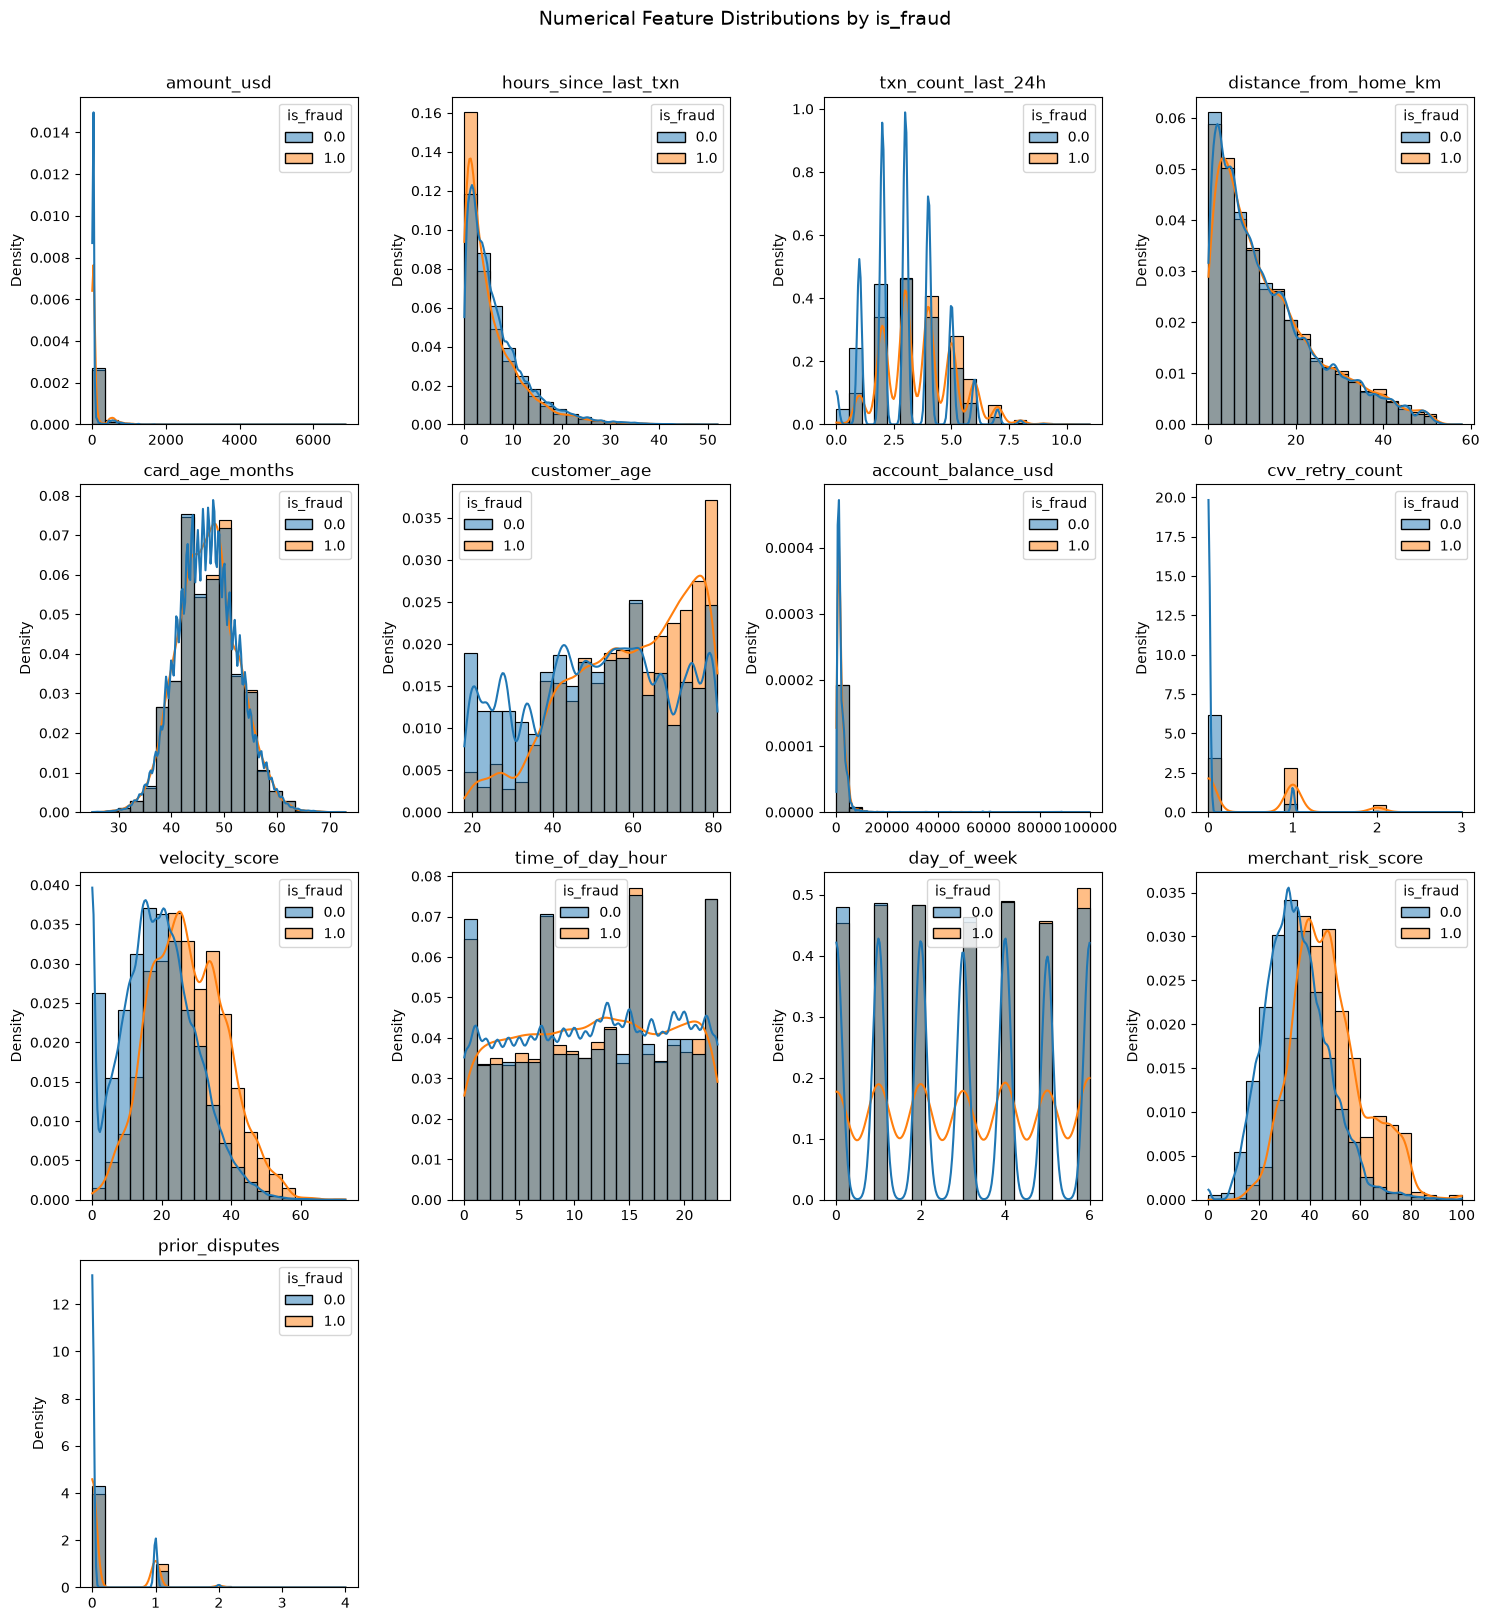

In [16]:
# Distribution of each numercial feature
n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df_train, x=col, hue='is_fraud', stat="density", common_norm=False, kde=True, ax=axes[i], bins=20)
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Feature Distributions by is_fraud', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

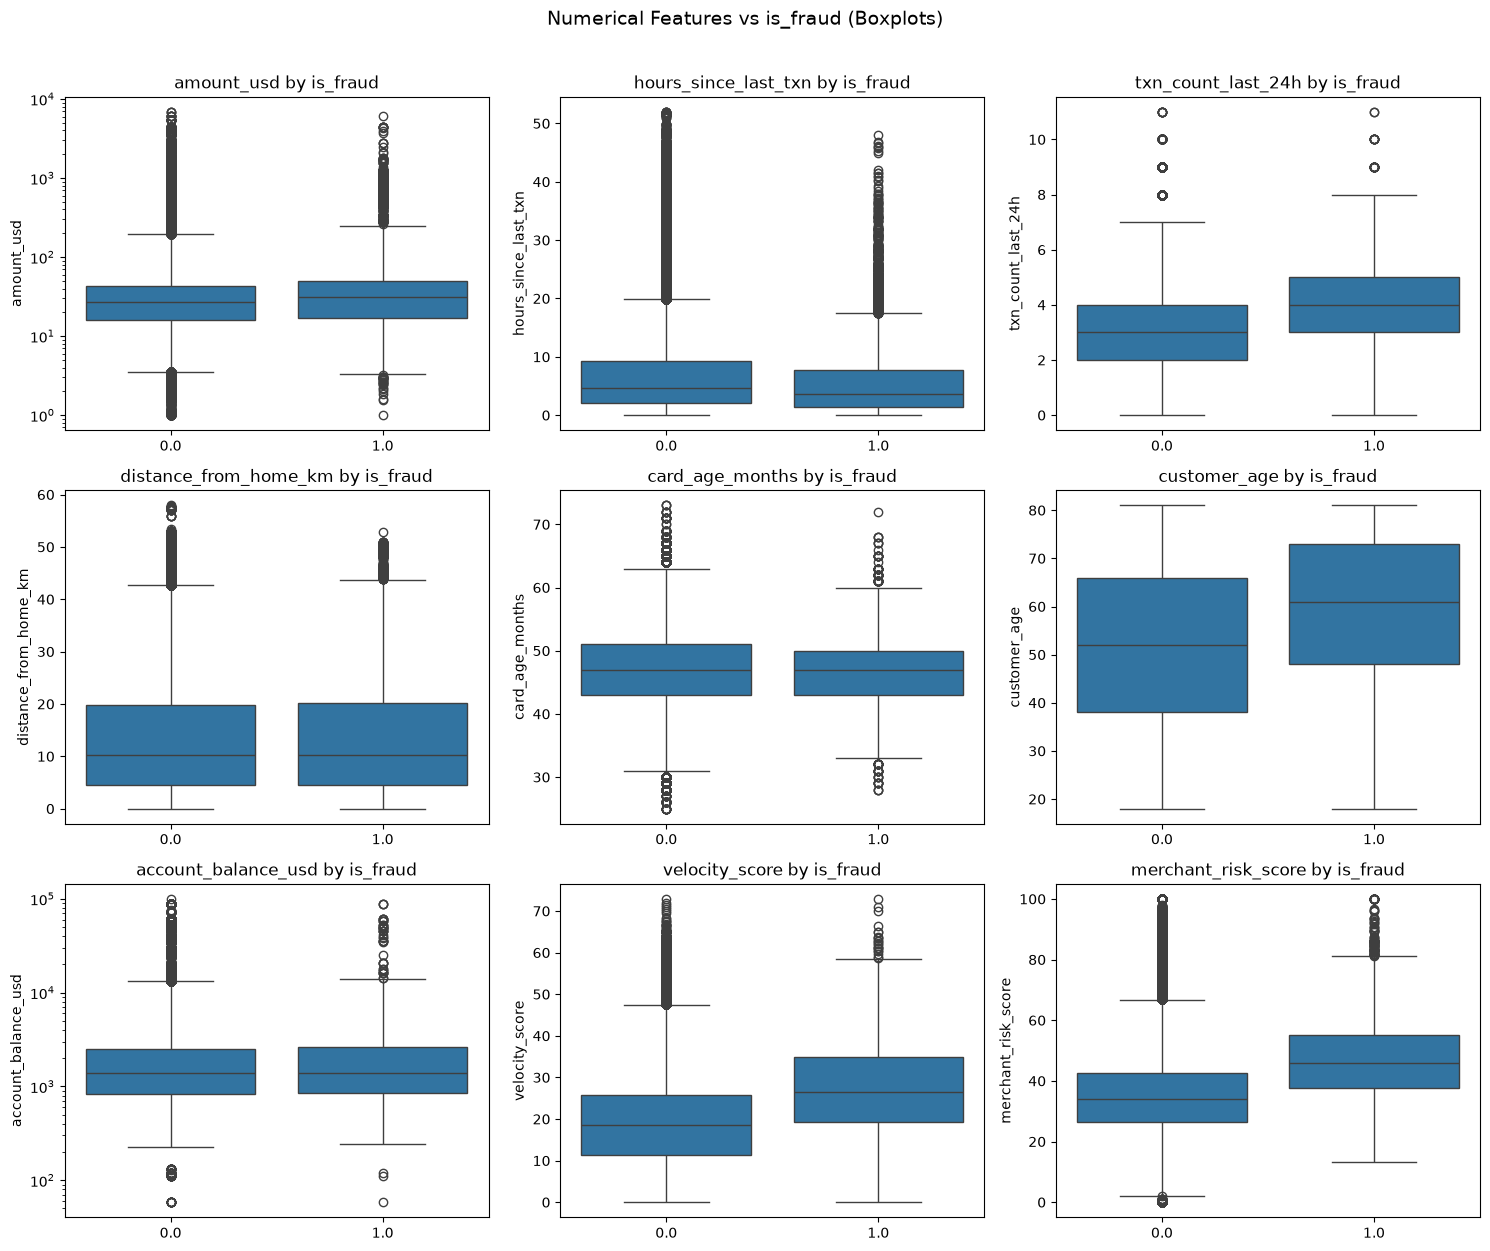

In [9]:
# Box plots: See spread, potential outliers
box_n_cols = 3
box_n_rows = 4
fig, axes = plt.subplots(box_n_rows, box_n_cols, figsize=(15, box_n_rows * 4))
axes = axes.flatten()
# skip some uninteresting features
skip_box_cols = ['cvv_retry_count', 'time_of_day_hour', 'day_of_week', 'prior_disputes']
box_cols = [c for c in num_cols if c not in skip_box_cols]

for i, col in enumerate(box_cols):
    if col in ["amount_usd", "account_balance_usd"]:
        axes[i].set_yscale("log")
    sns.boxplot(data=df_train, x='is_fraud', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by is_fraud')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Features vs is_fraud (Boxplots)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [15]:
# investigate amount_usd and account_balance_usd
df_train.groupby("is_fraud")[["amount_usd", "account_balance_usd"]].mean()

,amount_usd,account_balance_usd
is_fraud,,
0.0,79.373189,2064.520948
1.0,110.504532,2093.091944


In [11]:
df_train.groupby("is_fraud")[["amount_usd", "account_balance_usd"]].quantile([0.25, 0.5, 0.75])

amount_usd  account_balance_usd
is_fraud                                      
0.0      0.25       15.77               834.02
         0.50       27.21              1382.74
         0.75       42.95              2516.25
1.0      0.25       16.77               841.36
         0.50       31.18              1396.00
         0.75       49.89              2611.10

central distributions (central tendency) of these 2 features (by `is_fraud`) are mostly the same. 
This indicates that based on a that single feature and the interquartile range (IQR) alone, the two classes (not or is_fraud) show significant overlap and are difficult to separate.  
May have signal at the extremes, or when combine with other feature(s) 

potential numerical features:
```text
merchant_risk_score
velocity_score          # (maybe) the speed of txn made
hours_since_last_txn
txn_count_last_24h
customer_age
```

## 5. Categorical Feature Analysis

In [12]:
for col in cat_cols:
    print(f"{col}: {df_train[col].nunique()} unique values => {df_train[col].unique().tolist()}")

merchant_category: 12 unique values => ['Groceries', 'Online Retail', 'Utilities', 'Electronics', 'Healthcare', 'Restaurants', 'Fuel', 'Streaming', 'Crypto Exchange', 'Gaming', 'Travel', 'Gift Cards']
card_type: 5 unique values => ['Mastercard', 'Visa', 'Amex', 'RuPay', 'Discover']
auth_method: 5 unique values => ['OTP', 'PIN', '3D Secure', 'Biometric', 'No Authentication']
channel: 5 unique values => ['POS', 'In-App', 'Online', 'ATM', 'Contactless']
device_type: 8 unique values => ['iPhone', 'Android Phone', 'Tablet', 'Windows PC', 'POS Terminal', 'Mac', 'ATM Machine', 'Smart Watch']


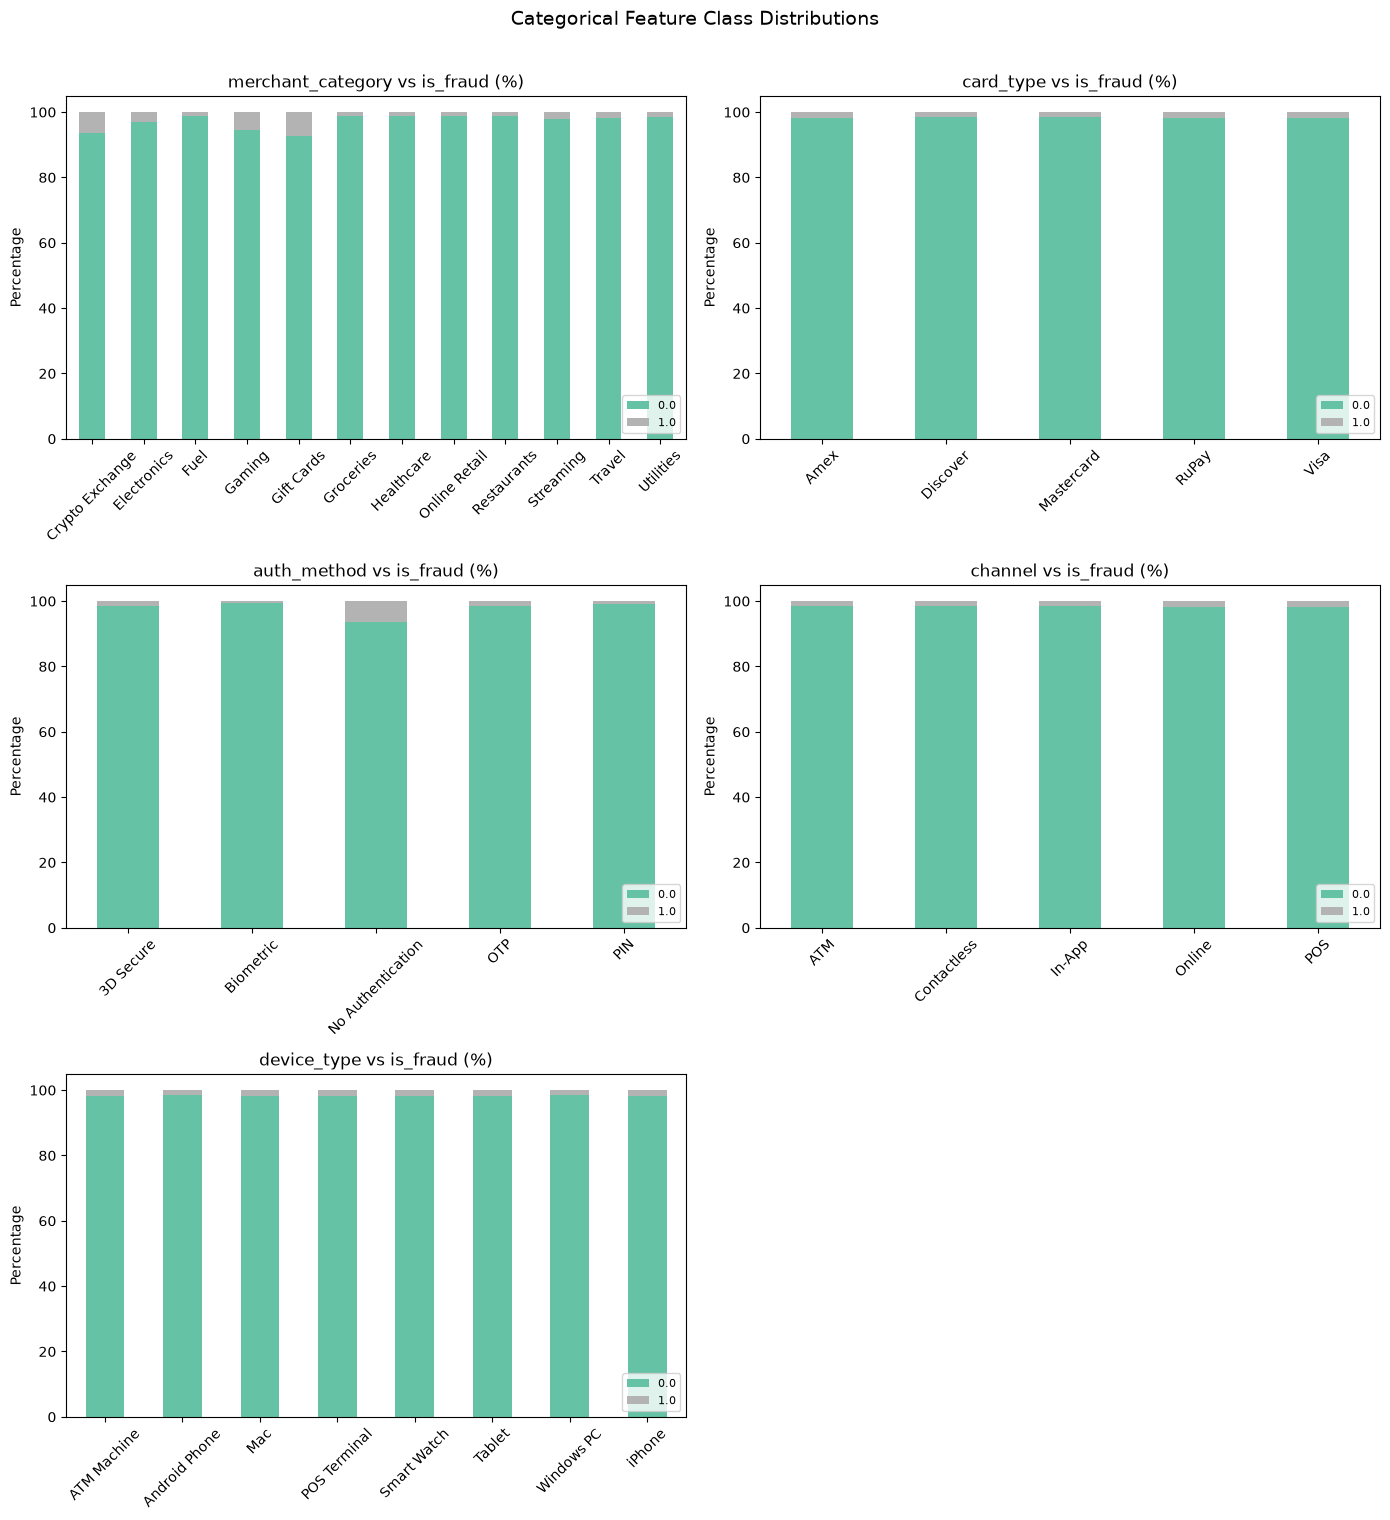

In [13]:
n_cols_plot = 2
n_rows_plot = int(np.ceil(len(cat_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(14, n_rows_plot * 5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df_train[col], df_train["is_fraud"], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i], colormap='Set2')
    axes[i].set_title(f'{col} vs is_fraud (%)')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Percentage')
    axes[i].legend(loc='lower right', fontsize=8)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Categorical Feature Class Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Prominent categorical features **associated to** fraud detection:
- merchant_category: Crypto Exchange, Gift card, Gaming
- auth_method: No Authentication
We are not sure if these categories and others actually have some kind of correlation. (Do they usually appear side by side, or interacts/influences each other, redundant, ....)

In [ ]:
def fraud_rate_by_features(features, train):
    for feat in features:
        summary = train.groupby(feat)["is_fraud"].agg(
            total="count",      # total txn
            fraud="sum",        # total fraud txn
            fraud_rate="mean"   # fraud rate, of all categorical features
        )
        summary["fraud_rate"] *= 100
        display(summary.sort_values("fraud_rate", ascending=False))

prominent_cat_feat = ["merchant_category", "auth_method"]
fraud_rate_by_features(prominent_cat_feat, df_train) # test assumption

In [18]:
# Bool features exploration
fraud_rate_by_features(bool_cols, df_train)

,total,fraud,fraud_rate
is_foreign_transaction,,,
True,12098,1521.0,12.572326
False,687862,10168.0,1.478203


,total,fraud,fraud_rate
is_new_merchant,,,
True,106720,5052.0,4.733883
False,593240,6637.0,1.118771


,total,fraud,fraud_rate
used_vpn,,,
True,23665,1550.0,6.549757
False,676295,10139.0,1.499198


,total,fraud,fraud_rate
ip_country_mismatch,,,
True,11312,1866.0,16.495757
False,688648,9823.0,1.426418


,total,fraud,fraud_rate
billing_shipping_mismatch,,,
True,9054,1176.0,12.988734
False,690906,10513.0,1.521625


,total,fraud,fraud_rate
is_ai_generated_scam_attempt,,,
True,2299,350.0,15.224010
False,697661,11339.0,1.625288


(All) looks promising!

## 6. Correlation Analysis of Numerical Features

We have the candidate features (when look at them separately)  
Now we want to know about how strong the correlation between the features to each other; in order to spot redundancy (multicollinearity) when it comes to predicting `is_fraud`. Especially important when training regression models.

#### 1. How features are related to each other?

In [ ]:
# Using Spearman as primary method to spot monotonic correlation
## Why? -> les vulnerable to outliers than pearson, continuous data in dataset (money amount, balance) is not normally distributed and contains potential outliers
# Using Pearson as secondary method to spot linear correlation (if can't infer from the result of Spearman)